# Lecture 07: Analyse an Environmental Sound (Option C)

**Assignment option:** C — analyse one supplied environmental recording.

**Recording:** `1-100032-A-0.wav` (class `dog`, training partition of the supplied ESC-50 subset).
Source: ESC-50, clip derived from *rose_bark.wav* by **nfrae** on Freesound
(<http://www.freesound.org/people/nfrae/sounds/100032/>), licensed **CC0**. The ESC-50 dataset as a whole is
CC BY-NC 3.0 (<https://github.com/karolpiczak/ESC-50>).

**Steps (from the assignment):**
1. Choose one supplied dog, rain, fire or clock-tick recording.
2. Listen to it. Plot its waveform and frequency spectrum.
3. Compare spectrograms with window lengths of 512 and 2048 samples. Use 16 kHz audio and a 160-sample hop for both.
4. Identify one relevant time interval and frequency region.
5. Explain the effect of window length and one limitation of the analysis.

The notebook reuses the lecture notebook's loading and spectrum code (`load_audio`, `spectrum`).
It runs on the CPU and needs only NumPy, SciPy, Matplotlib, pandas, librosa and soundfile.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import librosa, librosa.display
import soundfile as sf
from IPython.display import Audio, display

FS = 16000                    # analysis sample rate required by the assignment
HOP = 160                     # 10 ms hop at 16 kHz
WINDOWS = [512, 2048]         # STFT window lengths to compare
EVENT_THRESHOLD_DB = -20      # level that marks the event, relative to the loudest frame

CLIP = Path('data/1-100032-A-0.wav')
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)

def load_audio(path, target_rate=FS):
    # Same as the lecture notebook: mono mix, then resample to the analysis rate.
    x, rate = sf.read(str(path), dtype='float32', always_2d=True)
    x = x.mean(axis=1)
    assert len(x) > 0 and np.isfinite(x).all(), 'Invalid audio.'
    if rate != target_rate:
        x = librosa.resample(x, orig_sr=rate, target_sr=target_rate)
    return np.asarray(x, dtype=np.float32), rate

def spectrum(x, fs=FS):
    # Hann-windowed magnitude spectrum in dB relative to its maximum (lecture notebook).
    a = np.asarray(x, dtype=float); a = a - a.mean()
    s = np.abs(np.fft.rfft(a * np.hanning(len(a))))
    return np.fft.rfftfreq(len(a), 1 / fs), 20 * np.log10(np.maximum(s / max(s.max(), 1e-12), 1e-6))

def save_plot(name):
    plt.savefig(RESULTS / name, dpi=140, bbox_inches='tight'); plt.show()

x, original_rate = load_audio(CLIP)
t = np.arange(len(x)) / FS
info = sf.info(str(CLIP))
print(f'File: {CLIP.name}  original: {info.samplerate} Hz, {info.channels} channel(s), {info.subtype}')
print(f'Analysis signal: {FS} Hz, {len(x)} samples, {len(x) / FS:.2f} s, peak |x| = {np.abs(x).max():.3f}')
print(f'Exactly-zero samples: {100 * np.mean(x == 0):.1f} % of the clip')
display(Audio(x, rate=FS, normalize=False))

File: 1-100032-A-0.wav  original: 44100 Hz, 1 channel(s), PCM_16
Analysis signal: 16000 Hz, 80000 samples, 5.00 s, peak |x| = 0.984
Exactly-zero samples: 91.9 % of the clip


## Step 2 — Listen, waveform and spectrum

**Listening note:** the clip contains one short, sharp bark a little after two seconds. Before and after the bark there
is no audible background: ESC-50 pads short events with digital silence, which the zero-sample count above confirms.

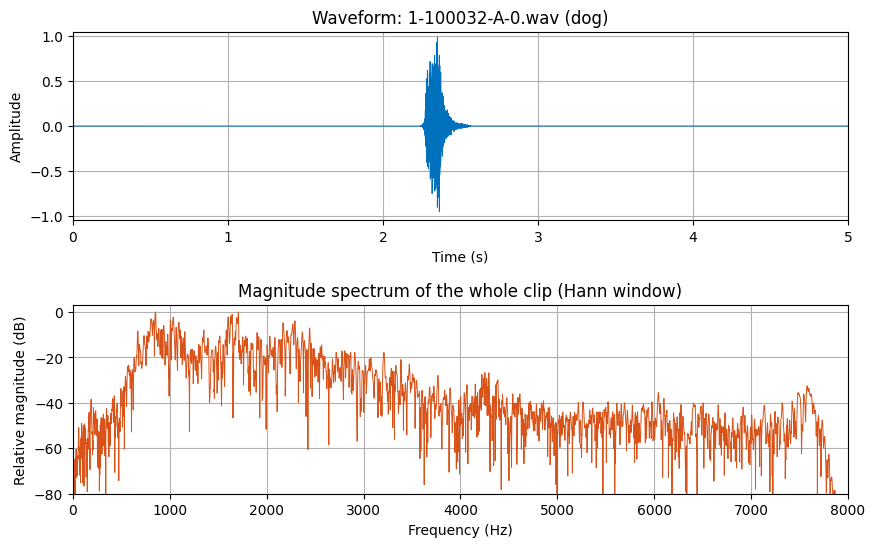

Cumulative energy reached at (Hz): {'10 %': 817, '50 %': 1599, '90 %': 2280, '99 %': 2917}
Energy above 8 kHz in the original 44100 Hz file: 0.14 %


In [2]:
f, d = spectrum(x)
fig, ax = plt.subplots(2, 1, figsize=(10, 6))
fig.subplots_adjust(hspace=.45)
ax[0].plot(t, x, lw=.7, color=(0, .4470, .7410))
ax[0].set(title=f'Waveform: {CLIP.name} (dog)', xlabel='Time (s)', ylabel='Amplitude', xlim=(0, len(x) / FS), ylim=(-1.05, 1.05))
ax[0].grid(True)
ax[1].plot(f, d, lw=.7, color=(.8500, .3250, .0980))
ax[1].set(title='Magnitude spectrum of the whole clip (Hann window)', xlabel='Frequency (Hz)', ylabel='Relative magnitude (dB)', xlim=(0, FS / 2), ylim=(-80, 3))
ax[1].grid(True)
save_plot('01_waveform_spectrum.png')

# Where the spectral energy lies: frequencies below which 10/50/90/99 % of the energy falls.
power = 10 ** (d / 10)
cumulative = np.cumsum(power) / power.sum()
energy_quantiles = {f'{int(q * 100)} %': round(float(f[np.searchsorted(cumulative, q)])) for q in [.1, .5, .9, .99]}
print('Cumulative energy reached at (Hz):', energy_quantiles)

# Energy the 16 kHz conversion discards: the part of the original recording above 8 kHz.
raw, raw_rate = sf.read(str(CLIP), dtype='float64')
raw_power = np.abs(np.fft.rfft(raw * np.hanning(len(raw)))) ** 2
raw_f = np.fft.rfftfreq(len(raw), 1 / raw_rate)
print(f'Energy above 8 kHz in the original {raw_rate} Hz file: {100 * raw_power[raw_f > 8000].sum() / raw_power.sum():.2f} %')

The waveform shows a single burst of about 0.2 s. The spectrum has no single dominant tone. Its energy is spread over a
band of peaks between roughly 0.7 and 2.5 kHz, and 99 % of the energy lies below about 2.9 kHz. The spectrum covers the whole 5 s
clip, so it says *which* frequencies are present but not *when*. Here that is harmless only because the rest of the clip
is silent. The spectrograms below add the timing information.

## Step 3 — Spectrograms with 512- and 2048-sample windows

Both use a Hann window, 16 kHz audio and a 160-sample (10 ms) hop. Only the window length changes. Both panels share the
same dB scale (relative to the loudest bin of each STFT) so the colours are comparable.

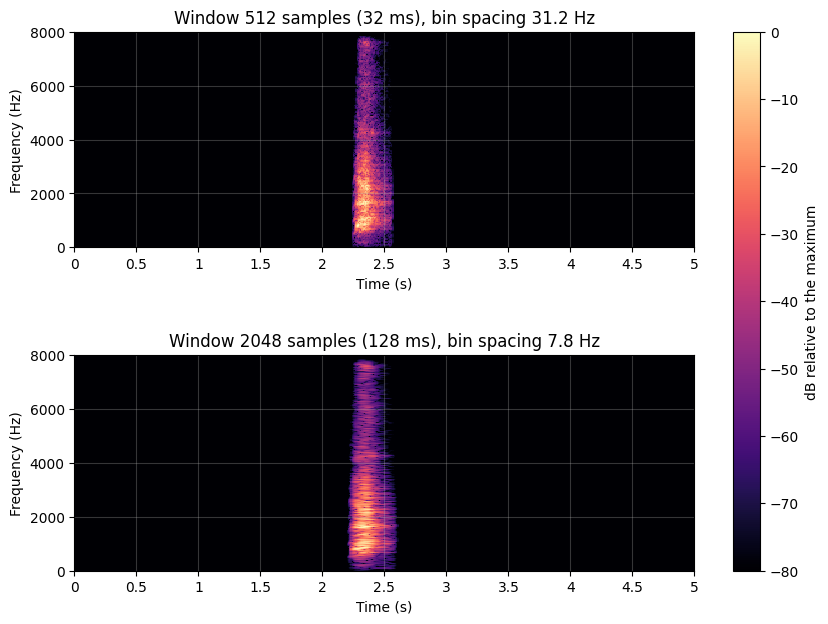

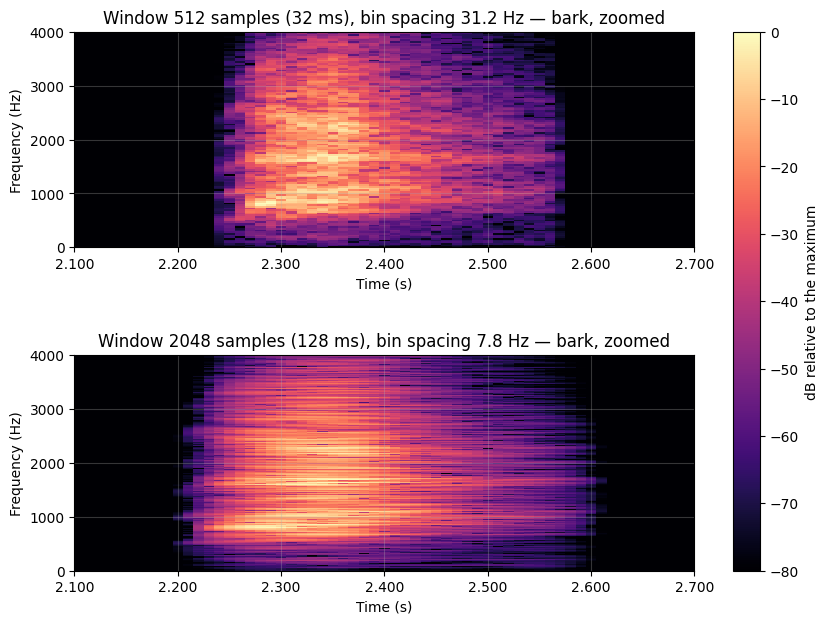

In [3]:
def stft_db(x, n_fft):
    S = np.abs(librosa.stft(x, n_fft=n_fft, hop_length=HOP, window='hann', center=True))
    return librosa.amplitude_to_db(S, ref=np.max)

specs = {n: stft_db(x, n) for n in WINDOWS}

def plot_specs(xlim, ylim, name, title_suffix, region=None):
    fig, axes = plt.subplots(2, 1, figsize=(10, 7))
    fig.subplots_adjust(hspace=.5)
    for ax, n in zip(axes, WINDOWS):
        im = librosa.display.specshow(specs[n], sr=FS, hop_length=HOP, x_axis='time', y_axis='linear',
                                      ax=ax, vmin=-80, vmax=0, cmap='magma')
        ax.set(title=f'Window {n} samples ({1000 * n / FS:.0f} ms), bin spacing {FS / n:.1f} Hz{title_suffix}',
               xlabel='Time (s)', ylabel='Frequency (Hz)', xlim=xlim, ylim=ylim)
        ax.grid(True, alpha=.3)
        if region is not None:
            (t0, t1), (f0, f1) = region
            ax.add_patch(Rectangle((t0, f0), t1 - t0, f1 - f0, fill=False, ec='cyan', lw=1.5, ls='--'))
    fig.colorbar(im, ax=axes, label='dB relative to the maximum')
    save_plot(name)

plot_specs((0, len(x) / FS), (0, FS / 2), '02_spectrograms_full.png', '')
plot_specs((2.1, 2.7), (0, 4000), '03_spectrograms_bark_zoom.png', ' — bark, zoomed')

## Window comparison in numbers

For each window length the cell below measures:

- **Time spread:** how long the frame energy stays within 20 dB of its maximum. A longer window starts to "see" the
  bark earlier and keeps seeing it later, so the event looks longer.
- **Frequency detail:** how many separate spectral peaks rise above −20 dB between 500 and 3000 Hz in the loudest
  frame. Finer bins can separate peaks that a short window merges.

In [4]:
from scipy import signal

rows = []
for n in WINDOWS:
    S = np.abs(librosa.stft(x, n_fft=n, hop_length=HOP, window='hann', center=True)) ** 2
    frame_db = 10 * np.log10(S.sum(axis=0) / S.sum(axis=0).max() + 1e-12)
    times = librosa.frames_to_time(np.arange(S.shape[1]), sr=FS, hop_length=HOP)
    active = times[frame_db > EVENT_THRESHOLD_DB]
    freqs = librosa.fft_frequencies(sr=FS, n_fft=n)
    loudest = 10 * np.log10(S[:, frame_db.argmax()] / S[:, frame_db.argmax()].max() + 1e-12)
    band = (freqs >= 500) & (freqs <= 3000)
    peaks, _ = signal.find_peaks(loudest[band], height=EVENT_THRESHOLD_DB)
    rows.append({'window_samples': n, 'window_ms': 1000 * n / FS, 'bin_spacing_hz': FS / n,
                 'event_start_s': round(active.min(), 3), 'event_end_s': round(active.max(), 3),
                 'event_duration_s': round(active.max() - active.min(), 3),
                 'peaks_500_3000hz': len(peaks)})
window_table = pd.DataFrame(rows)
window_table.to_csv(RESULTS / 'window_comparison.csv', index=False)
display(window_table)

,window_samples,window_ms,bin_spacing_hz,event_start_s,event_end_s,event_duration_s,peaks_500_3000hz
0,512,32.0,31.2500,2.27,2.43,0.16,15
1,2048,128.0,7.8125,2.24,2.45,0.21,63


## Step 4 — Relevant time interval and frequency region

The time interval comes from a fine 10 ms RMS envelope (independent of either STFT window). The frequency region is the
band that holds the central 80 % of the bark's energy (10 % to 90 % cumulative), measured on the bark segment only.

,event,start_s,end_s,duration_s,band_low_hz,band_high_hz,strongest_peak_hz
0,dog bark,2.275,2.442,0.167,854,2287,854


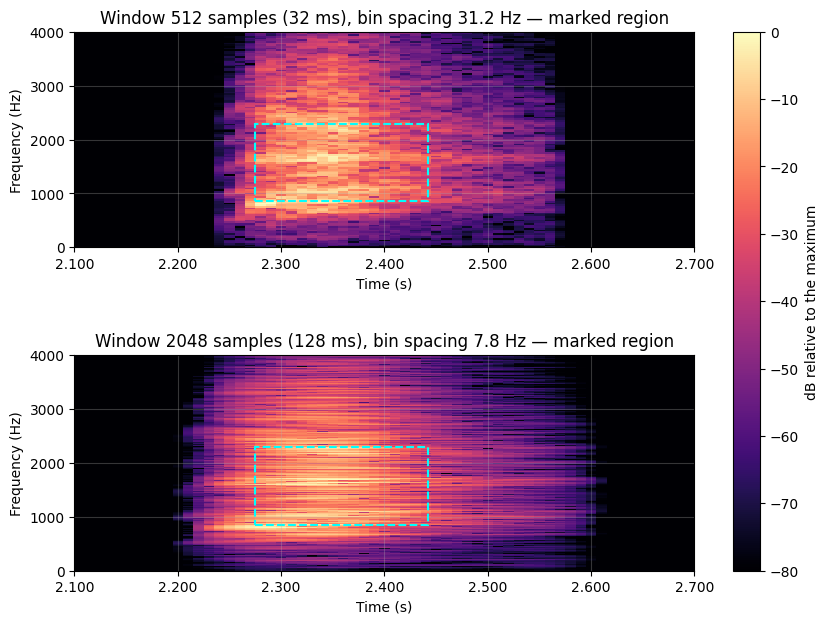

In [5]:
rms = librosa.feature.rms(y=x, frame_length=160, hop_length=40)[0]
rms_t = librosa.frames_to_time(np.arange(len(rms)), sr=FS, hop_length=40) + 80 / FS
rms_db = 20 * np.log10(rms / rms.max() + 1e-12)
on = rms_t[rms_db > EVENT_THRESHOLD_DB]
t0, t1 = float(on.min()), float(on.max())

segment = x[int(t0 * FS):int(t1 * FS)]
seg_f, seg_d = spectrum(segment)
seg_power = 10 ** (seg_d / 10)
seg_cum = np.cumsum(seg_power) / seg_power.sum()
f0, f1 = (float(seg_f[np.searchsorted(seg_cum, q)]) for q in (.1, .9))
peak_hz = float(seg_f[seg_d.argmax()])

region = pd.DataFrame([{'event': 'dog bark', 'start_s': round(t0, 3), 'end_s': round(t1, 3),
                        'duration_s': round(t1 - t0, 3), 'band_low_hz': round(f0), 'band_high_hz': round(f1),
                        'strongest_peak_hz': round(peak_hz)}])
region.to_csv(RESULTS / 'event_region.csv', index=False)
display(region)

plot_specs((2.1, 2.7), (0, 4000), '04_event_region.png', ' — marked region', region=((t0, t1), (f0, f1)))

## Step 5 — Effect of window length and limitations

**Selected region.** The bark lasts about 0.17 s, from about 2.28 s to 2.44 s. Its energy is concentrated between about
0.85 and 2.3 kHz (the marked rectangle). Both spectrograms show this band. Everything outside the rectangle in time is
silence.

**Effect of window length.**

- **512 samples (32 ms, 31.25 Hz bins)** localise the bark in time better. The event has sharp start and end edges and
  stays close to its true duration, but its spectral peaks blur into broad bands.
- **2048 samples (128 ms, 7.8 Hz bins)** separate nearby spectral peaks more clearly: the horizontal lines near 0.85, 1.6
  and 2.2 kHz are distinct. The table counts more peaks too, though part of that count is fine structure that only
  appears because there are four times as many bins. However, each frame covers 128 ms, so the 0.17 s bark is smeared over a longer time span. Its start appears
  earlier and its end later, and the onset edge is soft.
- This is the time–frequency trade-off of the STFT. The hop (10 ms) is the same for both, so it does not change the
  resolution: it only sets how often a frame is computed. The window length sets the resolution.

For a short, transient event such as a bark, the 512-sample window is the more useful view. The 2048-sample window
is better for steady sounds with closely spaced tones.

**Limitation.** This is one 5 s clip containing a single bark from one dog and one recording setup. The clip is about 92 % digital
zero padding, so it has no real background. The analysis says nothing about how the bark looks in noise or how other
dogs' barks vary, and it cannot show that this band identifies a dog on its own. The event boundaries also depend on the
chosen −20 dB threshold.

Converting to 16 kHz removes content above 8 kHz. For this file that is only about 0.1 % of the energy, so the effect is
negligible here, but it would matter for sounds with strong high-frequency content, such as rain or crackling fire.